# Lab 2 — What Did the Campaign Deliver?
Name: Yevhenii Kozlov | Group: KM-41

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

## Task 1.1 — Size

In [2]:
commercials_brand_A = commercials[commercials["brand"] == "BRAND_A"]

spots = len(commercials)
pods = len(commercials["pod_id"].unique())
brands = len(commercials["brand"].unique())
categories = len(commercials["category"].unique())

brand_A_spots = len(commercials_brand_A)
brand_A_spots_by_network = commercials_brand_A.groupby("network_code")["ad_airing_id"].count().sort_values(ascending=False)

print("Spots:", spots)
print("Pods:", pods)
print("Brands:", brands)
print("Categories:", categories)
print("BRAND_A spots:", brand_A_spots)
brand_A_spots_by_network

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


network_code
FNC      40
HGTV     39
FX       38
HIST     37
FOOD     33
BRAVO    33
ABC      29
CBS      22
NBC      16
FOX      13
Name: ad_airing_id, dtype: int64

## Task 1.2 — Ad load

In [3]:
def broadcast_hour(ts):
    """Calendar hour → broadcast-clock hour (6..29)."""
    h = ts.dt.hour
    return h.where(h >= 6, h + 24)

def broadcast_date(ts):
    """Calendar timestamp → broadcast date (flips at 06:00, not midnight)."""
    d = ts.dt.normalize()
    return d.where(ts.dt.hour >= 6, d - pd.Timedelta(days=1))

# Broadcast clock: hours 0-5 → 24-29, broadcast date shifts back one day
h = commercials['start_ts'].dt.hour
m = commercials['start_ts'].dt.minute
s = commercials['start_ts'].dt.second

bc_hour = broadcast_hour(commercials['start_ts'])
sec_in_hour = m * 60 + s  # seconds elapsed within the clock hour
bc_date = broadcast_date(commercials['start_ts'])

# Spots are ≤60s, so they cross at most one hour boundary
overflow = (sec_in_hour + commercials['length_sec'] - 3600).clip(lower=0)
main_secs = commercials['length_sec'] - overflow

# Main-hour contributions
main = pd.DataFrame({
    'network_code': commercials['network_code'],
    'bc_hour': bc_hour,
    'bc_date': bc_date,
    'ad_secs': main_secs
})

# Overflow into the next hour (rare, but correct)
ov_mask = overflow > 0
if ov_mask.any():
    ov_bc_hour = bc_hour[ov_mask] + 1
    ov_bc_date = bc_date[ov_mask]
    # Cap at broadcast clock boundary: hour 30 → hour 6 of next broadcast day
    wrap_mask = ov_bc_hour > 29
    ov_bc_hour = ov_bc_hour.where(~wrap_mask, 6)
    ov_bc_date = ov_bc_date.where(~wrap_mask, ov_bc_date + pd.Timedelta(days=1))
    ov = pd.DataFrame({
        'network_code': commercials.loc[ov_mask, 'network_code'],
        'bc_hour': ov_bc_hour,
        'bc_date': ov_bc_date,
        'ad_secs': overflow[ov_mask]
    })
    records = pd.concat([main, ov], ignore_index=True)
else:
    records = main

# Total ad seconds and number of broadcast days per (network, hour)
agg = records.groupby(['network_code', 'bc_hour']).agg(
    total_secs=('ad_secs', 'sum'),
    n_days=('bc_date', 'nunique')
)
agg['ad_min_per_hour'] = agg['total_secs'] / agg['n_days'] / 60

# Pivot into a table: rows = broadcast hours, columns = networks
table = agg['ad_min_per_hour'].unstack('network_code').fillna(0).round(1)
display(table)

# Heaviest = highest average ad minutes across hours that carried ads
avg_load = agg.groupby('network_code')['ad_min_per_hour'].mean()
print("Heaviest ad load:", avg_load.idxmax())

network_code,ABC,BRAVO,CBS,FNC,FOOD,FOX,FX,HGTV,HIST,NBC
bc_hour,,,,,,,,,,
6,15.1,13.8,0.0,15.4,13.4,0.0,12.9,13.2,13.2,0.0
7,14.5,13.8,13.7,16.6,12.8,0.0,13.0,13.1,13.1,14.4
8,15.5,13.6,15.0,16.3,12.7,0.0,12.7,13.1,13.2,15.6
9,0.3,13.4,12.7,15.6,13.2,0.0,12.9,13.8,13.1,13.5
10,13.6,13.7,11.0,16.2,13.0,15.8,13.2,13.8,12.8,13.6
11,14.3,13.6,13.5,15.2,13.3,13.7,13.3,13.7,13.0,0.9
12,8.0,13.7,7.8,15.0,13.1,12.7,12.9,13.6,13.2,0.0
13,13.4,13.6,14.2,15.4,12.9,12.2,12.8,13.0,13.2,0.0
14,13.5,13.3,14.2,16.2,13.1,13.3,13.0,13.2,13.5,0.0


Heaviest ad load: FNC


**Answer:** Broadcast networks have hours without national ads because during those hours the airtime belongs to local affiliate stations, which sell their own ads locally — these spots do not appear in the national ad log. In the late-night and early-morning hours, low viewership also makes the inventory less attractive to national advertisers.

## Task 1.3 — Price everything

In [4]:
# 1. Get program_name for each commercial
comms = commercials.merge(
    programs[['telecast_id', 'program_name']].drop_duplicates('telecast_id'),
    on='telecast_id', how='left'
)

# 2. Broadcast time and weekday for time-row matching
comms['bc_min']     = broadcast_hour(comms['start_ts']) * 60 + comms['start_ts'].dt.minute
comms['bc_weekday'] = broadcast_date(comms['start_ts']).dt.weekday   # 0 = Mon

# ── 3. Price from PROGRAM rows (program row wins over time row) ──────────
rc_prog = (rate_card
           .dropna(subset=['program_name'])
           [['network_code', 'program_name', 'cost_30s_usd']])

comms = comms.merge(rc_prog, on=['network_code', 'program_name'], how='left')
comms.rename(columns={'cost_30s_usd': 'cost_30s'}, inplace=True)
comms['from_program'] = comms['cost_30s'].notna()

# ── 4. Price from TIME rows (for spots still unpriced) ───────────────────
rc_time = rate_card[rate_card['program_name'].isna()].copy()

# Convert "HH:MM" strings to total minutes for comparison
to_min = lambda t: int(t.split(':')[0]) * 60 + int(t.split(':')[1])
rc_time['start_min'] = rc_time['start_time'].apply(to_min)
rc_time['end_min']   = rc_time['end_time'].apply(to_min)

# Explode weekdays list so each day becomes its own row
rc_time = (rc_time
           [['network_code', 'weekdays', 'start_min', 'end_min', 'cost_30s_usd']]
           .explode('weekdays'))
rc_time['weekdays'] = rc_time['weekdays'].astype(int)

# Match unpriced spots by network + weekday, then filter by time range
unpriced = (comms[comms['cost_30s'].isna()]
            [['network_code', 'bc_min', 'bc_weekday']]
            .reset_index())

matched = (unpriced
           .merge(rc_time,
                  left_on=['network_code', 'bc_weekday'],
                  right_on=['network_code', 'weekdays'])
           .query('bc_min >= start_min and bc_min < end_min')
           .drop_duplicates('index')
           .set_index('index'))

comms.loc[matched.index, 'cost_30s'] = matched['cost_30s_usd']

# ── 5. Spot cost: :15 = half the :30 price, :60 = double ─────────────────
comms['cost_usd'] = comms['cost_30s'] * comms['length_sec'] / 30

print("Spots without a price:", comms['cost_usd'].isna().sum())

# ── 6. Table: rate-card value by network (USD M) and program-row share ───
total = comms.groupby('network_code')['cost_usd'].sum()
prog  = comms[comms['from_program']].groupby('network_code')['cost_usd'].sum()

result = pd.DataFrame({
    'value_M':       (total / 1e6).round(1),
    'program_share': (prog / total).fillna(0).round(3)
})
display(result)

Spots without a price: 0


,value_M,program_share
network_code,,
ABC,708.8,0.432
BRAVO,25.3,0.000
CBS,818.8,0.230
FNC,315.8,0.000
FOOD,42.1,0.000
FOX,696.2,0.835
FX,42.5,0.000
HGTV,58.1,0.000
HIST,40.1,0.000


## Task 2.1 — Delivery

In [5]:
# ── Build exposures: one row per (BRAND_A spot × person who saw it) ──────
brand_a = commercials_brand_A.copy()
brand_a['bc_date'] = broadcast_date(brand_a['start_ts'])

rl_viewings = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
rl_viewings['bc_date'] = broadcast_date(rl_viewings['start_ts'])

# Saw a spot = watching that network when the spot started
exposures = (
    brand_a[['ad_airing_id', 'network_code', 'start_ts', 'bc_date']]
    .merge(
        rl_viewings[['respondent_id', 'network_code', 'start_ts', 'end_ts', 'bc_date']],
        on=['network_code', 'bc_date'],
        suffixes=('_spot', '_view')
    )
    .query('start_ts_view <= start_ts_spot and start_ts_spot < end_ts')
    [['ad_airing_id', 'respondent_id', 'network_code', 'bc_date']]
    .drop_duplicates(['ad_airing_id', 'respondent_id'])
)

# Add daily weight for the spot's broadcast day
rl_dw = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].copy()
rl_dw['broadcast_date'] = pd.to_datetime(rl_dw['broadcast_date'])

exposures = exposures.merge(
    rl_dw[['respondent_id', 'broadcast_date', 'weight']],
    left_on=['respondent_id', 'bc_date'],
    right_on=['respondent_id', 'broadcast_date']
).drop(columns='broadcast_date')

# ── Audience sets ────────────────────────────────────────────────────────
p2_ids = set(rl_dw['respondent_id'].unique())

ages = viewer_attributes[viewer_attributes['attr_id'] == 300]
a18_49_ids = set(ages.loc[(ages['value'] >= 18) & (ages['value'] <= 49), 'respondent_id']) & p2_ids

# ── Delivery metrics ─────────────────────────────────────────────────────
def compute_delivery(exposures, person_ids, dw):
    """Impressions, GRPs, reach (%), avg frequency for an audience."""
    exp = exposures[exposures['respondent_id'].isin(person_ids)]
    dw_aud = dw[dw['respondent_id'].isin(person_ids)]

    # Universe per broadcast day = sum of weights of all in-tab persons
    universe = dw_aud.groupby('broadcast_date')['weight'].sum()

    # Per-spot: impressions and rating
    spot = (exp.groupby(['ad_airing_id', 'bc_date'])['weight']
            .sum().reset_index(name='imp'))
    spot['universe'] = spot['bc_date'].map(universe)
    spot['rating']   = spot['imp'] / spot['universe'] * 100

    impressions = spot['imp'].sum()
    grps        = spot['rating'].sum()

    # Reach = monthly-weight of reached persons / total monthly-weight × 100
    monthly_w = dw_aud.groupby('respondent_id')['weight'].mean()
    reached   = set(exp['respondent_id'].unique())
    reach     = monthly_w[monthly_w.index.isin(reached)].sum() / monthly_w.sum() * 100

    avg_freq = grps / reach
    return impressions, grps, reach, avg_freq

# ── Results ──────────────────────────────────────────────────────────────
imp_p2,  grps_p2,  reach_p2,  freq_p2  = compute_delivery(exposures, p2_ids,     rl_dw)
imp_a18, grps_a18, reach_a18, freq_a18 = compute_delivery(exposures, a18_49_ids, rl_dw)

print("P2+ impressions (M):",      round(imp_p2 / 1e6, 1))
print("P2+ GRPs:",                 round(grps_p2, 1))
print("P2+ reach (%):",            round(reach_p2, 1))
print("P2+ average frequency:",    round(freq_p2, 1))
print("A18-49 impressions (M):",   round(imp_a18 / 1e6, 1))
print("A18-49 GRPs:",              round(grps_a18, 1))
print("A18-49 reach (%):",         round(reach_a18, 1))
print("A18-49 average frequency:", round(freq_a18, 1))

P2+ impressions (M): 418.7
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

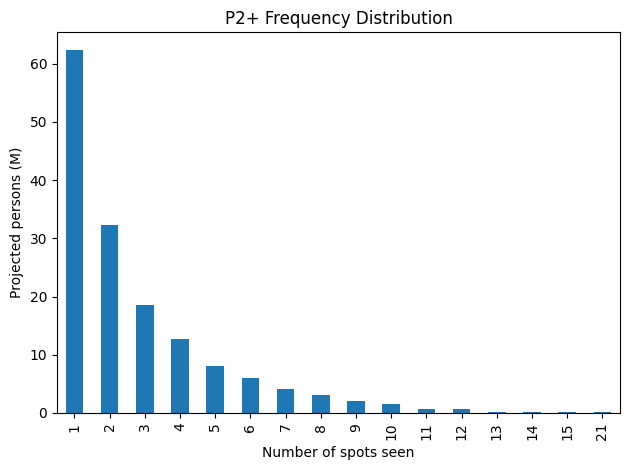

Share of impressions at 5+ exposures: 0.444


In [6]:
# P2+ exposures
exp_p2 = exposures[exposures['respondent_id'].isin(p2_ids)]

# Monthly weight per person (average daily weight across in-tab days)
monthly_w_p2 = (rl_dw[rl_dw['respondent_id'].isin(p2_ids)]
                .groupby('respondent_id')['weight'].mean())

# Frequency: how many BRAND_A spots each person saw
person_freq = exp_p2.groupby('respondent_id')['ad_airing_id'].nunique().rename('n_spots')

# ── Plot: projected persons (M) by number of spots seen ──────────────────
freq_dist = (person_freq.reset_index()
             .merge(monthly_w_p2.rename('monthly_w').reset_index(), on='respondent_id'))

proj_persons = freq_dist.groupby('n_spots')['monthly_w'].sum() / 1e6

proj_persons.plot(kind='bar', xlabel='Number of spots seen', ylabel='Projected persons (M)')
plt.title('P2+ Frequency Distribution')
plt.tight_layout()
plt.show()

# ── Share of impressions at 5+ exposures ─────────────────────────────────
person_imp = exp_p2.groupby('respondent_id')['weight'].sum()
persons_5plus = set(person_freq[person_freq >= 5].index)
share_5plus = person_imp[person_imp.index.isin(persons_5plus)].sum() / person_imp.sum()

print("Share of impressions at 5+ exposures:", round(share_5plus, 3))

In [7]:
print("Median frequency:", person_freq.median())

Median frequency: 2.0


**Answer:** The average frequency is not a fair summary because the distribution is right-skewed. A large share of impressions (44.4%) comes from people who saw the commercial 5 or more times, while the median frequency is only 2 — suggesting that the typical viewer's exposure is closer to 2 than to the reported average of 3.

## Task 2.3 — On target?

In [8]:
# ── Overall on-target share ──────────────────────────────────────────────
on_target_share = imp_a18 / imp_p2
print(f"Share of impressions on A18-49: {on_target_share:.3f}")

# ── On-target share by network ───────────────────────────────────────────
exp_p2  = exposures[exposures['respondent_id'].isin(p2_ids)]
exp_a18 = exposures[exposures['respondent_id'].isin(a18_49_ids)]

imp_by_net_p2  = exp_p2.groupby('network_code')['weight'].sum()
imp_by_net_a18 = exp_a18.groupby('network_code')['weight'].sum()

net_share = (imp_by_net_a18 / imp_by_net_p2).round(3)

result = pd.DataFrame({
    'imp_P2_M':     (imp_by_net_p2  / 1e6).round(1),
    'imp_A18_49_M': (imp_by_net_a18 / 1e6).round(1),
    'on_target':     net_share
}).sort_values('on_target', ascending=False)

display(result)

Share of impressions on A18-49: 0.194


,imp_P2_M,imp_A18_49_M,on_target
network_code,,,
FX,8.5,5.6,0.651
BRAVO,5.1,2.8,0.554
FOOD,9.5,3.0,0.316
HGTV,24.7,7.6,0.306
FOX,76.3,18.4,0.242
HIST,12.3,2.5,0.202
NBC,41.4,7.8,0.189
ABC,94.2,17.0,0.180
CBS,89.0,13.7,0.154


**Answer:** Overall, our campaign under-delivered against the target — only 19.4% of impressions fell on A18-49 versus the 42% target. This happened because most networks have an on-target share well below 42%, and the two networks that exceed it (FX and BRAVO) contribute too few impressions to move the overall number.

## Task 3.1 — Cost

In [9]:
# ── Campaign cost (BRAND_A only) ─────────────────────────────────────────
brand_a_costs = comms[comms['brand'] == 'BRAND_A']
campaign_cost = brand_a_costs['cost_usd'].sum()

# ── CPM = cost / impressions × 1000 ─────────────────────────────────────
cpm_p2  = campaign_cost / imp_p2  * 1000
cpm_a18 = campaign_cost / imp_a18 * 1000

# ── CPP = cost / GRPs ───────────────────────────────────────────────────
cpp_p2  = campaign_cost / grps_p2
cpp_a18 = campaign_cost / grps_a18

print(f"Campaign cost (USD): {campaign_cost:,.0f}")
print(f"P2+ CPM (USD): {cpm_p2:.2f}")
print(f"P2+ CPP (USD): {cpp_p2:,.0f}")
print(f"A18-49 CPM (USD): {cpm_a18:.2f}")
print(f"A18-49 CPP (USD): {cpp_a18:,.0f}")

Campaign cost (USD): 7,420,270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56,224
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122,836


## Task 3.2 — By network

In [10]:
# ── Cost by network (BRAND_A only) ───────────────────────────────────────
cost_by_net = brand_a_costs.groupby('network_code')['cost_usd'].sum()
spots_by_net = brand_a_costs.groupby('network_code').size()

# CPM = cost / impressions × 1000
cpm_p2_net  = cost_by_net / imp_by_net_p2  * 1000
cpm_a18_net = cost_by_net / imp_by_net_a18 * 1000

net_table = pd.DataFrame({
    'spots':       spots_by_net,
    'cost':        cost_by_net.round(0).astype(int),
    'imp_P2_M':    (imp_by_net_p2  / 1e6).round(1),
    'imp_A18_49_M':(imp_by_net_a18 / 1e6).round(1),
    'CPM_P2':      cpm_p2_net.round(2),
    'CPM_A18_49':  cpm_a18_net.round(2)
}).sort_values('cost', ascending=False)

display(net_table)

,spots,cost,imp_P2_M,imp_A18_49_M,CPM_P2,CPM_A18_49
network_code,,,,,,
FOX,13,2434700,76.3,18.4,31.93,132.03
ABC,29,1625700,94.2,17.0,17.26,95.69
CBS,22,1488700,89.0,13.7,16.73,108.72
NBC,16,796800,41.4,7.8,19.23,101.72
FNC,40,526300,57.8,2.7,9.11,193.70
HGTV,39,230000,24.7,7.6,9.33,30.45
FOOD,33,96620,9.5,3.0,10.19,32.29
FX,38,92200,8.5,5.6,10.82,16.61
HIST,37,79640,12.3,2.5,6.46,32.05


**Answer:** Most of the money went to big networks (ABC, CBS, NBC, FOX, FNC), which carry far fewer BRAND_A spots but at much higher unit costs. The cheapest network to reach the A18-49 target is FX, with the lowest CPM on the target demo — though it also delivers relatively few total impressions.

## Task 3.3 — Guarantee

In [11]:
TARGET_GRPS_P2 = 150
make_good_grps = TARGET_GRPS_P2 - grps_p2
value_of_make_goods = make_good_grps * cpp_p2

print("Guarantee met:", grps_p2 > TARGET_GRPS_P2)  # True / False
print("Make-good GRPs owed:", round(make_good_grps))
print("Value of make-goods (USD):", round(value_of_make_goods))

Guarantee met: False
Make-good GRPs owed: 18
Value of make-goods (USD): 1013358


## Task 4 — Do networks add up?

In [12]:
# ── Network groups ───────────────────────────────────────────────────────
big   = {'CBS', 'NBC', 'ABC', 'FOX', 'FNC'}
small = {'FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST'}

# P2+ monthly weights
monthly_w_p2 = (rl_dw[rl_dw['respondent_id'].isin(p2_ids)]
                .groupby('respondent_id')['weight'].mean())
total_mw = monthly_w_p2.sum()

# Reached persons per group
exp_p2 = exposures[exposures['respondent_id'].isin(p2_ids)]
reached_big   = set(exp_p2[exp_p2['network_code'].isin(big)]['respondent_id'])
reached_small = set(exp_p2[exp_p2['network_code'].isin(small)]['respondent_id'])
reached_all   = set(exp_p2['respondent_id'])

# Reach = sum of monthly weights of reached / total × 100
reach_big   = monthly_w_p2[monthly_w_p2.index.isin(reached_big)].sum()   / total_mw * 100
reach_small = monthly_w_p2[monthly_w_p2.index.isin(reached_small)].sum() / total_mw * 100
reach_all   = monthly_w_p2[monthly_w_p2.index.isin(reached_all)].sum()   / total_mw * 100

# Overlap and independence check
overlap       = reach_big + reach_small - reach_all
overlap_indep = reach_big * reach_small / 100

# Incremental reach from small networks
added_reach = reach_all - reach_big

# Cost per reach point
cost_big   = brand_a_costs[brand_a_costs['network_code'].isin(big)]['cost_usd'].sum()
cost_small = brand_a_costs[brand_a_costs['network_code'].isin(small)]['cost_usd'].sum()

print(f"Reach, big networks (%): {reach_big:.1f}")
print(f"Reach, small networks (%): {reach_small:.1f}")
print(f"Reach, whole campaign (%): {reach_all:.1f}")
print(f"Overlap (%): {overlap:.1f}")
print(f"Overlap if independent (%): {overlap_indep:.1f}")
print(f"Reach added by small networks (points): {added_reach:.1f}")
print(f"Cost per added reach point, small (USD): {cost_small / added_reach:,.0f}")
print(f"Cost per reach point, big (USD): {cost_big / reach_big:,.0f}")

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148,706
Cost per reach point, big (USD): 172,456


**Answer:** Reach does not add up because the same person can see an ad on both big and small networks, creating overlap. The actual overlap (8.7%) is greater than what we would expect under independence (4.9%), meaning small-network viewers are more likely to be reached by big networks than the average person — probably because heavy TV viewers tend to watch both. The small networks added 3.7 points of incremental reach at a cost of $148,706 per point, which is cheaper than the $172,456 per reach point on big networks, so the money was spent effectively.

## Task 5 — How sure are we?

In [13]:
import numpy as np

# ── Panelists per spot (unweighted count, P2+) ──────────────────────────
exp_p2 = exposures[exposures['respondent_id'].isin(p2_ids)]

panelist_counts = (exp_p2.groupby('ad_airing_id')['respondent_id']
                   .nunique().rename('n_panelists'))

all_spots = commercials_brand_A[['ad_airing_id', 'network_code', 'start_ts']].copy()
all_spots['bc_date'] = broadcast_date(all_spots['start_ts'])
spots_pan = all_spots.merge(panelist_counts, on='ad_airing_id', how='left')
spots_pan['n_panelists'] = spots_pan['n_panelists'].fillna(0).astype(int)

# ── Per-spot P2+ rating ──────────────────────────────────────────────────
dw_p2 = rl_dw[rl_dw['respondent_id'].isin(p2_ids)]
universe_w = dw_p2.groupby('broadcast_date')['weight'].sum()
universe_n = dw_p2.groupby('broadcast_date')['respondent_id'].nunique()

spot_imp = (exp_p2.groupby(['ad_airing_id', 'bc_date'])['weight']
            .sum().reset_index(name='imp'))
spot_imp['universe_w'] = spot_imp['bc_date'].map(universe_w)
spot_imp['rating']     = spot_imp['imp'] / spot_imp['universe_w'] * 100
spot_imp['n_intab']    = spot_imp['bc_date'].map(universe_n)

spots_pan = spots_pan.merge(
    spot_imp[['ad_airing_id', 'rating', 'n_intab']],
    on='ad_airing_id', how='left'
)
spots_pan['rating']  = spots_pan['rating'].fillna(0)
spots_pan['n_intab'] = spots_pan['n_intab'].fillna(
    spots_pan['bc_date'].map(universe_n))

# ── SE = sqrt(p(1-p)/n) × 100; relative SE = SE / rating ────────────────
p = spots_pan['rating'] / 100
n = spots_pan['n_intab']
spots_pan['se'] = np.sqrt(p * (1 - p) / n) * 100
spots_pan['rel_se'] = np.where(spots_pan['rating'] > 0,
                               spots_pan['se'] / spots_pan['rating'],
                               np.nan)

# ── Table by network ─────────────────────────────────────────────────────
net_stats = spots_pan.groupby('network_code').agg(
    median_panelists=('n_panelists', 'median'),
    median_rel_se=('rel_se', 'median')
).round(3)
display(net_stats)

print(f"Spots seen by no panelist: {(spots_pan['n_panelists'] == 0).sum()}")
print(f"Median relative SE, big networks: "
      f"{spots_pan[spots_pan['network_code'].isin(big)]['rel_se'].median():.3f}")
print(f"Median relative SE, small networks: "
      f"{spots_pan[spots_pan['network_code'].isin(small)]['rel_se'].median():.3f}")

# ── W18-34 zero-cell spots ──────────────────────────────────────────────
female_ids = set(viewer_attributes[viewer_attributes['attr_id'] == 202]['respondent_id'])
age_18_34  = set(ages.loc[(ages['value'] >= 18) & (ages['value'] <= 34),
                          'respondent_id'])
w18_34_ids = female_ids & age_18_34 & p2_ids

exp_w = exposures[exposures['respondent_id'].isin(w18_34_ids)]
w_counts = exp_w.groupby('ad_airing_id')['respondent_id'].nunique()
spots_w = all_spots.merge(w_counts.rename('n'), on='ad_airing_id', how='left')
spots_w['n'] = spots_w['n'].fillna(0).astype(int)

print(f"W18-34 zero-cell spots: {(spots_w['n'] == 0).sum()}")

,median_panelists,median_rel_se
network_code,,
ABC,57.0,0.123
BRAVO,3.0,0.540
CBS,69.0,0.113
FNC,31.0,0.164
FOOD,5.0,0.423
FOX,145.0,0.080
FX,5.5,0.423
HGTV,11.0,0.301
HIST,5.0,0.460


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** Spots seen by no panelist (10 spots) receive a zero rating. This does not mean that nobody watched them in reality — it simply means that our panel is too small to capture any viewers in those cases. In addition, a large share of the spots (171 out of 300) were not seen by any W18-34 panelist, so they receive a zero rating in this demographic. We cannot reliably estimate ratings for such narrow groups because the results are too unstable and unrepresentative.

## Bonus

In [14]:
# ── Bonus: move 20 spots from FNC → 10 HGTV + 10 FX ─────────────────────

# Average cost per spot on each network
avg_cost_fnc  = brand_a_costs[brand_a_costs['network_code'] == 'FNC']['cost_usd'].mean()
avg_cost_hgtv = brand_a_costs[brand_a_costs['network_code'] == 'HGTV']['cost_usd'].mean()
avg_cost_fx   = brand_a_costs[brand_a_costs['network_code'] == 'FX']['cost_usd'].mean()

# Cost of 20 removed FNC spots
cost_removed = 20 * avg_cost_fnc

# Cost of 10 HGTV + 10 FX spots
cost_added = 10 * avg_cost_hgtv + 10 * avg_cost_fx

# Budget saved
budget_diff = cost_removed - cost_added

# Average impressions per spot per network (A18-49)
n_fnc  = brand_a_costs[brand_a_costs['network_code'] == 'FNC'].shape[0]
n_hgtv = brand_a_costs[brand_a_costs['network_code'] == 'HGTV'].shape[0]
n_fx   = brand_a_costs[brand_a_costs['network_code'] == 'FX'].shape[0]

imp_per_spot_fnc  = imp_by_net_a18['FNC']  / n_fnc
imp_per_spot_hgtv = imp_by_net_a18['HGTV'] / n_hgtv
imp_per_spot_fx   = imp_by_net_a18['FX']   / n_fx

# Impressions lost and gained (A18-49)
imp_lost  = 20 * imp_per_spot_fnc
imp_gained = 10 * imp_per_spot_hgtv + 10 * imp_per_spot_fx

# Same for P2+
imp_per_spot_fnc_p2  = imp_by_net_p2['FNC']  / n_fnc
imp_per_spot_hgtv_p2 = imp_by_net_p2['HGTV'] / n_hgtv
imp_per_spot_fx_p2   = imp_by_net_p2['FX']   / n_fx

imp_lost_p2  = 20 * imp_per_spot_fnc_p2
imp_gained_p2 = 10 * imp_per_spot_hgtv_p2 + 10 * imp_per_spot_fx_p2

# New campaign totals
new_cost    = campaign_cost - cost_removed + cost_added
new_imp_a18 = imp_a18 - imp_lost + imp_gained
new_imp_p2  = imp_p2  - imp_lost_p2 + imp_gained_p2

new_cpm_a18 = new_cost / new_imp_a18 * 1000
new_cpm_p2  = new_cost / new_imp_p2  * 1000

# On-target share
new_on_target = new_imp_a18 / new_imp_p2

print("=== REMOVED: 20 FNC spots ===")
print(f"Cost removed (USD): {cost_removed:,.0f}")
print(f"A18-49 impressions lost (M): {imp_lost / 1e6:.1f}")
print(f"P2+ impressions lost (M): {imp_lost_p2 / 1e6:.1f}")

print("\n=== ADDED: 10 HGTV + 10 FX spots ===")
print(f"Cost added (USD): {cost_added:,.0f}")
print(f"A18-49 impressions gained (M): {imp_gained / 1e6:.1f}")
print(f"P2+ impressions gained (M): {imp_gained_p2 / 1e6:.1f}")

print(f"\n=== BUDGET ===")
print(f"Budget saved (USD): {budget_diff:,.0f}")

print(f"\n=== CAMPAIGN: BEFORE → AFTER ===")
print(f"Cost (USD): {campaign_cost:,.0f} → {new_cost:,.0f}")
print(f"A18-49 impressions (M): {imp_a18 / 1e6:.1f} → {new_imp_a18 / 1e6:.1f}")
print(f"A18-49 CPM (USD): {cpm_a18:.2f} → {new_cpm_a18:.2f}")
print(f"On-target share: {imp_a18 / imp_p2:.3f} → {new_on_target:.3f}")

=== REMOVED: 20 FNC spots ===
Cost removed (USD): 263,150
A18-49 impressions lost (M): 1.4
P2+ impressions lost (M): 28.9

=== ADDED: 10 HGTV + 10 FX spots ===
Cost added (USD): 83,238
A18-49 impressions gained (M): 3.4
P2+ impressions gained (M): 8.6

=== BUDGET ===
Budget saved (USD): 179,912

=== CAMPAIGN: BEFORE → AFTER ===
Cost (USD): 7,420,270 → 7,240,358
A18-49 impressions (M): 81.1 → 83.1
A18-49 CPM (USD): 91.53 → 87.12
On-target share: 0.194 → 0.209


**Answer:** I propose moving 20 spots from FNC to HGTV (10) and FX (10). FNC has the worst on-target share (0.047) and the highest A18-49 CPM ($193.70), meaning nearly all of its impressions reach viewers outside our target demographic. HGTV and FX offer much better target efficiency, with A18-49 CPMs of $30.45 and $16.61 respectively. The reallocation saves $179,912 in budget while gaining 2.0M net A18-49 impressions, bringing the campaign A18-49 CPM down from $91.53 to $87.12 and raising the on-target share from 0.194 to 0.209. The trade-off is a loss of 20.3M P2+ impressions, but since the campaign's core weakness is poor target delivery rather than insufficient total volume, this is a worthwhile exchange.